# Questão 3: MLP e CNN na base CIFAR-10

A CIFAR-10 tem 60 mil imagens coloridas pequenas (32 x 32 pixels), divididas em 10 classes: avião, automóvel, pássaro, gato, cervo, cachorro, sapo, cavalo, navio e caminhão.

Nesta questão treinamos dois classificadores e comparamos os resultados:
- item a: uma rede MLP, que recebe a imagem "achatada" em uma lista de números;
- item b: uma rede convolucional (CNN), que olha a imagem como imagem, analisando pedaços vizinhos de pixels.

Para cada um mostramos a arquitetura, as curvas de erro, a matriz de confusão e a acurácia no teste.

## Bibliotecas

In [1]:
import copy
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from torch import nn
from torchvision import datasets
from tqdm import tqdm

# usa a placa de vídeo se tiver, senão usa o processador
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Rodando em:", device)

PASTA_DADOS = Path("../data/cifar10")
PASTA_MODELOS = Path("../checkpoints")
PASTA_FIGURAS = Path("../figures/q3")
PASTA_MODELOS.mkdir(parents=True, exist_ok=True)
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 110

CLASSES = ["avião", "automóvel", "pássaro", "gato", "cervo", "cachorro", "sapo", "cavalo", "navio", "caminhão"]

Rodando em: cuda


## Funções

Aqui ficam todas as funções que usamos no notebook. Cada uma tem uma explicação curta logo acima.

### fixar_semente
Fixa a "semente" dos sorteios (pesos iniciais, embaralhamento, data augmentation) e pede para a placa de vídeo usar sempre os mesmos algoritmos. Assim o resultado é o mesmo toda vez que o notebook for executado.

In [2]:
def fixar_semente(semente=42):
    random.seed(semente)
    np.random.seed(semente)
    torch.manual_seed(semente)
    torch.cuda.manual_seed_all(semente)
    # faz a placa de vídeo usar sempre os mesmos algoritmos, para o resultado não variar entre execuções
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

### carregar_cifar
Baixa a CIFAR-10 (só na primeira vez) e devolve as imagens e as classes como arrays. As imagens vêm no formato (quantidade, altura, largura, cor), com valores de 0 a 255.

In [3]:
def carregar_cifar():
    treino = datasets.CIFAR10(PASTA_DADOS, train=True, download=True)
    teste = datasets.CIFAR10(PASTA_DADOS, train=False, download=True)
    return treino.data, np.array(treino.targets), teste.data, np.array(teste.targets)

### para_tensor
Prepara as imagens para a rede:
1. muda a ordem para (quantidade, cor, altura, largura), que é a ordem usada pelo PyTorch;
2. divide por 255 para os pixels ficarem entre 0 e 1;
3. normaliza cada canal de cor (vermelho, verde, azul) com a média e o desvio calculados no treino.

Tudo vai direto para a placa de vídeo, o que deixa o treino bem mais rápido.

In [4]:
def para_tensor(imagens, media, desvio):
    x = torch.tensor(imagens, dtype=torch.float32, device=device).permute(0, 3, 1, 2) / 255.0
    return (x - media.view(1, 3, 1, 1)) / desvio.view(1, 3, 1, 1)

### aumentar_dados
Data augmentation: a cada lote, criamos versões levemente diferentes das imagens de treino. Fazemos duas coisas:
- espelhamos metade das imagens na horizontal (um carro virado para a esquerda continua sendo um carro);
- deslocamos cada imagem até 4 pixels para os lados e para cima ou para baixo (preenchendo a borda com o reflexo da imagem).

Assim a rede quase nunca vê exatamente a mesma imagem duas vezes, o que dificulta que ela decore o treino.

In [5]:
def aumentar_dados(x):
    n = x.shape[0]
    # espelhamento horizontal em metade das imagens
    espelhar = torch.rand(n, device=x.device) < 0.5
    x = torch.where(espelhar.view(-1, 1, 1, 1), x.flip(3), x)
    # deslocamento aleatório de até 4 pixels
    x = F.pad(x, (4, 4, 4, 4), mode="reflect")
    desloc_linha = torch.randint(0, 9, (n,), device=x.device)
    desloc_coluna = torch.randint(0, 9, (n,), device=x.device)
    posicoes = torch.arange(32, device=x.device)
    linhas = (desloc_linha.view(-1, 1) + posicoes).view(n, 1, 32, 1).expand(n, 3, 32, 40)
    colunas = (desloc_coluna.view(-1, 1) + posicoes).view(n, 1, 1, 32).expand(n, 3, 32, 32)
    x = x.gather(2, linhas)  # escolhe 32 linhas a partir do deslocamento
    return x.gather(3, colunas)  # escolhe 32 colunas a partir do deslocamento

### para_exibir
Desfaz a normalização de uma imagem (volta para as cores originais, com pixels entre 0 e 1) e muda a ordem para (altura, largura, cor), que é o formato que o matplotlib usa para desenhar.

In [6]:
def para_exibir(x, media, desvio):
    return (x * desvio.view(3, 1, 1) + media.view(3, 1, 1)).clamp(0, 1).permute(1, 2, 0).cpu().numpy()

### lotes
Divide as imagens em lotes (pedaços) de um tamanho fixo. No treino os lotes são sorteados de novo a cada época.

In [7]:
def lotes(X, y, tamanho_lote, embaralhar):
    ordem = torch.randperm(len(X), device=X.device) if embaralhar else torch.arange(len(X), device=X.device)
    for inicio in range(0, len(X), tamanho_lote):
        indices = ordem[inicio:inicio + tamanho_lote]
        yield X[indices], y[indices]

### MLP
A rede do item a. A imagem de 32 x 32 pixels com 3 cores vira uma lista de 3072 números (32 x 32 x 3). Depois vêm três camadas escondidas (1024, 512 e 256 neurônios) e a saída com 10 neurônios, um por classe.

Em cada camada escondida usamos:
- BatchNorm: normaliza os valores dentro da rede, o que deixa o treino mais estável e mais rápido;
- ReLU: a função de ativação;
- Dropout de 30%: desliga neurônios ao acaso no treino, para evitar overfitting.

In [8]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        camadas = []
        anterior = 3 * 32 * 32
        for neuronios in [1024, 512, 256]:
            camadas += [nn.Linear(anterior, neuronios), nn.BatchNorm1d(neuronios), nn.ReLU(), nn.Dropout(0.3)]
            anterior = neuronios
        camadas.append(nn.Linear(anterior, 10))
        self.rede = nn.Sequential(nn.Flatten(), *camadas)

    def forward(self, x):
        return self.rede(x)

### bloco_convolucional
Um "bloco" da CNN: duas convoluções seguidas, cada uma com BatchNorm e ReLU, e depois um MaxPool, que reduz a imagem pela metade (por exemplo, de 32 x 32 para 16 x 16), e um Dropout.

A convolução passa pequenos filtros de 3 x 3 pixels por toda a imagem. Cada filtro aprende a detectar um padrão (uma borda, uma cor, uma textura) em qualquer lugar da imagem.

In [9]:
def bloco_convolucional(entrada, saida, dropout):
    return nn.Sequential(
        nn.Conv2d(entrada, saida, kernel_size=3, padding=1),
        nn.BatchNorm2d(saida),
        nn.ReLU(),
        nn.Conv2d(saida, saida, kernel_size=3, padding=1),
        nn.BatchNorm2d(saida),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Dropout(dropout),
    )

### CNN
A rede do item b, com três blocos convolucionais:
- bloco 1: 64 filtros, imagem de 32 x 32 vira 16 x 16;
- bloco 2: 128 filtros, 16 x 16 vira 8 x 8;
- bloco 3: 256 filtros, 8 x 8 vira 4 x 4.

No final, o "global average pooling" tira a média de cada um dos 256 mapas, gerando 256 números, e uma camada linear transforma isso nas 10 classes.

Quanto mais fundo o bloco, mais complexos são os padrões: o primeiro bloco detecta bordas e cores, e os últimos detectam partes de objetos (rodas, olhos, asas).

In [10]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.bloco1 = bloco_convolucional(3, 64, dropout=0.1)
        self.bloco2 = bloco_convolucional(64, 128, dropout=0.2)
        self.bloco3 = bloco_convolucional(128, 256, dropout=0.3)
        self.saida = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(256, 10))

    def forward(self, x):
        return self.saida(self.bloco3(self.bloco2(self.bloco1(x))))

### rodar_epoca
Passa uma vez por todos os lotes e devolve o erro médio (entropia cruzada) e a acurácia.
- Com otimizador, a rede aprende. Se `aumentar` for verdadeiro, as imagens passam pela data augmentation antes.
- Sem otimizador, a rede só é avaliada.

Usamos "precisão mista" (autocast): a placa de vídeo faz parte das contas com números menores (16 bits), o que deixa o treino mais rápido e gasta menos memória, praticamente sem mudar o resultado.

In [11]:
def rodar_epoca(modelo, X, y, tamanho_lote, otimizador=None, agendador=None, escalador=None, aumentar=False):
    treinando = otimizador is not None
    modelo.train(treinando)
    funcao_erro = nn.CrossEntropyLoss()
    erro_total, acertos = 0.0, 0
    with torch.set_grad_enabled(treinando):
        for x, alvo in lotes(X, y, tamanho_lote, embaralhar=treinando):
            if aumentar:
                x = aumentar_dados(x)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"):
                saida = modelo(x)
                erro = funcao_erro(saida, alvo)
            if treinando:
                otimizador.zero_grad()
                escalador.scale(erro).backward()
                escalador.step(otimizador)
                escalador.update()
                if agendador is not None:
                    agendador.step()
            erro_total += erro.item() * len(x)
            acertos += (saida.argmax(dim=1) == alvo).sum().item()
    return erro_total / len(X), acertos / len(X)

### treinar
Treina a rede por várias épocas. A cada época:
1. a rede aprende com o treino;
2. medimos o erro e a acurácia na validação;
3. guardamos os pesos da época com a maior acurácia na validação.

Opções:
- `paciencia`: se a acurácia da validação passar esse número de épocas sem melhorar, o treino para (early stopping);
- `one_cycle`: usa o agendador OneCycle, que começa com uma taxa de aprendizado baixa, aumenta até o máximo e depois vai diminuindo até quase zero. Isso costuma deixar a CNN mais precisa no final do treino;
- `aumentar`: liga a data augmentation;
- `salvar_epocas`: lista de épocas em que salvamos uma cópia dos pesos em arquivo (usamos isso na Questão 4 para ver como a rede muda ao longo do treino).

A barra de progresso mostra o erro e a acurácia de treino e de validação.

In [12]:
def treinar(modelo, dados, epocas, lr, weight_decay=0.0, paciencia=None, one_cycle=False,
            aumentar=False, tamanho_lote=128, salvar_epocas=(), nome_arquivo=None, extras=None, nome="Treinando"):
    X_treino, y_treino, X_val, y_val = dados
    otimizador = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=weight_decay)
    agendador = None
    if one_cycle:
        passos = (len(X_treino) + tamanho_lote - 1) // tamanho_lote
        agendador = torch.optim.lr_scheduler.OneCycleLR(otimizador, max_lr=lr, epochs=epocas, steps_per_epoch=passos)
    escalador = torch.amp.GradScaler(enabled=device.type == "cuda")

    historico = {"erro_treino": [], "erro_val": [], "acc_treino": [], "acc_val": [], "melhor_epoca": 0}
    melhor_acc = -1.0
    melhores_pesos = None
    epocas_sem_melhorar = 0
    inicio = time.time()

    barra = tqdm(range(1, epocas + 1), desc=nome, unit="época", ncols=110, mininterval=2)
    for epoca in barra:
        erro_tr, acc_tr = rodar_epoca(modelo, X_treino, y_treino, tamanho_lote, otimizador, agendador, escalador, aumentar)
        erro_val, acc_val = rodar_epoca(modelo, X_val, y_val, 1000)
        historico["erro_treino"].append(erro_tr)
        historico["erro_val"].append(erro_val)
        historico["acc_treino"].append(acc_tr)
        historico["acc_val"].append(acc_val)

        # se o erro virou NaN ou infinito, o treino "explodiu" e não adianta continuar
        if not np.isfinite(erro_tr) or not np.isfinite(erro_val):
            raise RuntimeError(f"O erro deixou de ser um número na época {epoca}. Tente uma taxa de aprendizado menor.")

        if acc_val > melhor_acc:
            melhor_acc = acc_val
            melhores_pesos = copy.deepcopy(modelo.state_dict())
            historico["melhor_epoca"] = epoca
            epocas_sem_melhorar = 0
        else:
            epocas_sem_melhorar += 1

        if epoca in salvar_epocas:
            salvar_modelo(modelo, PASTA_MODELOS / f"{nome_arquivo}_epoca_{epoca:02d}.pt", epoca, extras)

        barra.set_postfix(acc_treino=f"{acc_tr:.3f}", acc_val=f"{acc_val:.3f}",
                          erro_val=f"{erro_val:.3f}", melhor=historico["melhor_epoca"], refresh=False)

        if paciencia is not None and epocas_sem_melhorar >= paciencia:
            barra.close()
            print(f"Parou na época {epoca}: a acurácia da validação ficou {paciencia} épocas sem melhorar.")
            break

    modelo.load_state_dict(melhores_pesos)
    minutos = (time.time() - inicio) / 60
    print(f"Melhor época: {historico['melhor_epoca']} (acurácia na validação = {melhor_acc:.4f}). Tempo: {minutos:.1f} min")
    return historico

### salvar_modelo
Salva os pesos da rede em um arquivo, junto com a época e a média e o desvio usados na normalização. A Questão 4 precisa dessas informações para usar a mesma rede.

In [13]:
def salvar_modelo(modelo, caminho, epoca, extras=None):
    torch.save({"pesos": modelo.state_dict(), "epoca": epoca, **(extras or {})}, caminho)

### prever
Devolve a classe prevista e as probabilidades de cada classe (softmax) para um conjunto de imagens. Processa em lotes de 1000 imagens para não estourar a memória da placa de vídeo.

In [14]:
def prever(modelo, X):
    modelo.eval()
    probabilidades = []
    with torch.no_grad():
        for inicio in range(0, len(X), 1000):
            saida = modelo(X[inicio:inicio + 1000])
            probabilidades.append(torch.softmax(saida.float(), dim=1).cpu())
    probabilidades = torch.cat(probabilidades).numpy()
    return probabilidades.argmax(axis=1), probabilidades

### acuracia_por_classe
Para cada classe, calcula a porcentagem de imagens daquela classe que a rede acertou.

In [15]:
def acuracia_por_classe(y_real, y_previsto):
    return pd.Series({classe: (y_previsto[y_real == i] == i).mean() for i, classe in enumerate(CLASSES)})

### grafico_curvas
Desenha o erro e a acurácia de treino e de validação ao longo das épocas. A linha tracejada marca a melhor época, cujos pesos a rede usa no final.

In [16]:
def grafico_curvas(historico, titulo, arquivo=None):
    epocas = range(1, len(historico["erro_treino"]) + 1)
    melhor = historico["melhor_epoca"]
    fig, (esquerda, direita) = plt.subplots(1, 2, figsize=(13, 4.5))
    esquerda.plot(epocas, historico["erro_treino"], label="treino")
    esquerda.plot(epocas, historico["erro_val"], label="validação")
    esquerda.set_ylabel("erro (entropia cruzada)")
    direita.plot(epocas, historico["acc_treino"], label="treino")
    direita.plot(epocas, historico["acc_val"], label="validação")
    direita.set_ylabel("acurácia")
    for eixo in (esquerda, direita):
        eixo.axvline(melhor, color="gray", linestyle="--", label=f"melhor época ({melhor})")
        eixo.set_xlabel("época")
        eixo.legend()
        eixo.grid(alpha=0.3)
    fig.suptitle(titulo)
    plt.tight_layout()
    if arquivo:
        plt.savefig(PASTA_FIGURAS / arquivo, bbox_inches="tight")
    plt.show()

### grafico_matriz_confusao
Desenha a matriz de confusão. Cada linha é a classe real e cada coluna é a classe prevista. Cada classe tem 1000 imagens no teste, então os números da diagonal são quantas das 1000 a rede acertou.

In [17]:
def grafico_matriz_confusao(y_real, y_previsto, titulo, arquivo=None):
    matriz = confusion_matrix(y_real, y_previsto)
    plt.figure(figsize=(10, 8))
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=CLASSES, yticklabels=CLASSES)
    plt.xlabel("classe prevista")
    plt.ylabel("classe real")
    plt.title(titulo)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    if arquivo:
        plt.savefig(PASTA_FIGURAS / arquivo, bbox_inches="tight")
    plt.show()
    return matriz

### maiores_confusoes
Lista os pares de classes que a rede mais confunde (fora da diagonal da matriz de confusão).

In [18]:
def maiores_confusoes(matriz, quantidade=5):
    pares = []
    for real in range(10):
        for previsto in range(10):
            if real != previsto:
                pares.append({"classe real": CLASSES[real], "prevista como": CLASSES[previsto], "imagens": matriz[real, previsto]})
    return pd.DataFrame(pares).sort_values("imagens", ascending=False).head(quantidade).reset_index(drop=True)

### tabela_overfitting
Calcula a acurácia em treino, validação e teste lado a lado. Se o treino for muito melhor que os outros dois, a rede decorou o treino.

In [19]:
def tabela_overfitting(modelo, conjuntos):
    linhas = {}
    for nome, (X, y) in conjuntos.items():
        previstos, _ = prever(modelo, X)
        linhas[nome] = {"acurácia": (previstos == y.cpu().numpy()).mean()}
    return pd.DataFrame(linhas).T

---
# Preparando os dados

## Carregando a base

In [20]:
imagens_treino, classes_treino, imagens_teste, classes_teste = carregar_cifar()
print("Imagens de treino:", imagens_treino.shape)
print("Imagens de teste:", imagens_teste.shape)

Imagens de treino: (50000, 32, 32, 3)
Imagens de teste: (10000, 32, 32, 3)


## Quantidade de imagens por classe

In [21]:
pd.DataFrame({
    "treino": np.bincount(classes_treino),
    "teste": np.bincount(classes_teste),
}, index=CLASSES)

,treino,teste
avião,5000,1000
automóvel,5000,1000
pássaro,5000,1000
gato,5000,1000
cervo,5000,1000
cachorro,5000,1000
sapo,5000,1000
cavalo,5000,1000
navio,5000,1000
caminhão,5000,1000


As 10 classes têm exatamente a mesma quantidade de imagens: 5000 no treino e 1000 no teste. A base é balanceada, então a acurácia é uma boa métrica aqui e não precisamos de técnicas de balanceamento.

## Exemplos de cada classe

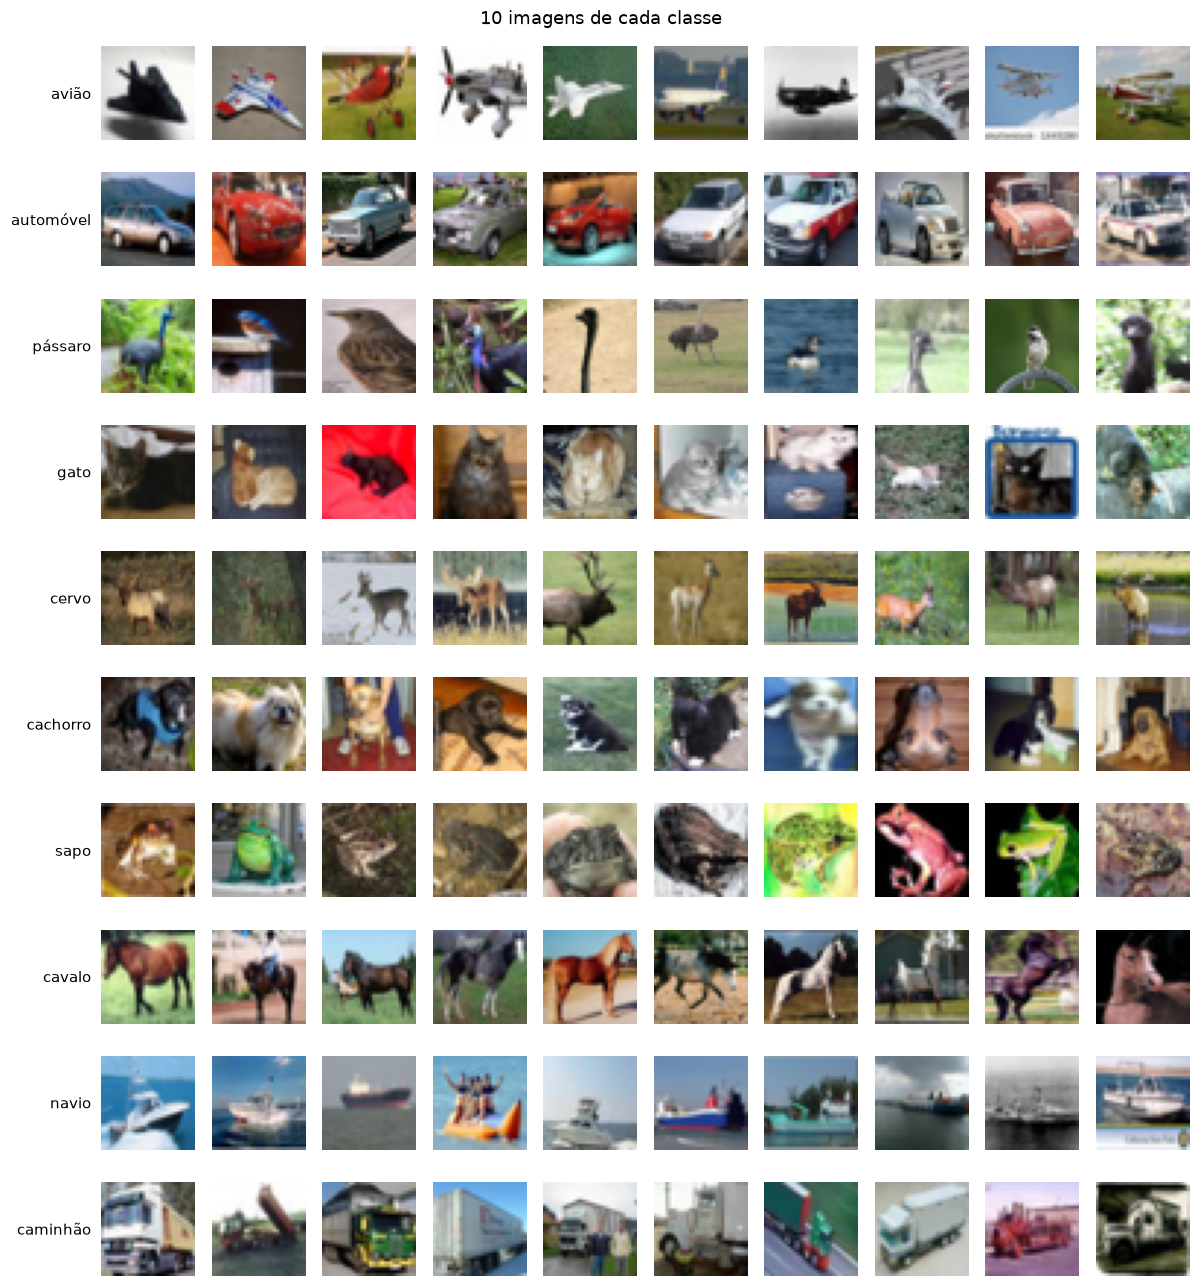

In [22]:
fig, eixos = plt.subplots(10, 10, figsize=(11, 12))
for i, classe in enumerate(CLASSES):
    exemplos = np.where(classes_treino == i)[0][:10]
    for j, indice in enumerate(exemplos):
        eixos[i, j].imshow(imagens_treino[indice])
        eixos[i, j].axis("off")
    eixos[i, 0].text(-4, 16, classe, ha="right", va="center", fontsize=10)
plt.suptitle("10 imagens de cada classe")
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "3_exemplos.png", bbox_inches="tight")
plt.show()

O que observar:
- As imagens são muito pequenas (32x32 pixels). Mesmo para uma pessoa, algumas são difíceis de reconhecer.
- Dentro de uma mesma classe as fotos variam muito: pássaros podem ser um avestruz ou um passarinho, aparecer de frente ou de lado, com fundo de céu, grama ou água.
- O fundo ajuda e atrapalha: aviões e navios costumam ter céu ou água azul atrás, e cervos e cavalos costumam ter grama verde. A rede pode aprender a usar o fundo como pista.
- Gato e cachorro são parecidos em tamanho, cor e pose (deitados, de frente). Já dá para esperar que esse par seja o mais confundido.

## Separando a validação
Tiramos 5000 imagens do treino (500 de cada classe) para a validação. Ficam 45 mil para treinar. As 10 mil imagens de teste só são usadas no final.

In [23]:
indices = np.arange(len(imagens_treino))
indices_treino, indices_val = train_test_split(indices, test_size=5000, stratify=classes_treino, random_state=42)
print("Treino:", len(indices_treino))
print("Validação:", len(indices_val))
print("Teste:", len(imagens_teste))

Treino: 45000
Validação: 5000
Teste: 10000


## Normalizando
Calculamos a média e o desvio de cada canal de cor (vermelho, verde e azul) usando só as imagens de treino.

In [24]:
pixels_treino = imagens_treino[indices_treino] / 255.0
media = torch.tensor(pixels_treino.mean(axis=(0, 1, 2)), dtype=torch.float32, device=device)
desvio = torch.tensor(pixels_treino.std(axis=(0, 1, 2)), dtype=torch.float32, device=device)
del pixels_treino
print("Média (R, G, B):", media.cpu().numpy().round(3))
print("Desvio (R, G, B):", desvio.cpu().numpy().round(3))

Média (R, G, B): [0.491 0.482 0.446]
Desvio (R, G, B): [0.247 0.243 0.262]


## Levando os dados para a placa de vídeo

In [25]:
X_treino = para_tensor(imagens_treino[indices_treino], media, desvio)
X_val = para_tensor(imagens_treino[indices_val], media, desvio)
X_teste = para_tensor(imagens_teste, media, desvio)
y_treino = torch.tensor(classes_treino[indices_treino], device=device)
y_val = torch.tensor(classes_treino[indices_val], device=device)
y_teste = torch.tensor(classes_teste, device=device)

dados = (X_treino, y_treino, X_val, y_val)
conjuntos = {"treino": (X_treino, y_treino), "validação": (X_val, y_val), "teste": (X_teste, y_teste)}
print("Formato do treino:", tuple(X_treino.shape))

Formato do treino: (45000, 3, 32, 32)


## Exemplo da data augmentation
Na primeira coluna está a imagem original e nas outras, versões criadas pela data augmentation, como a CNN vai ver durante o treino.

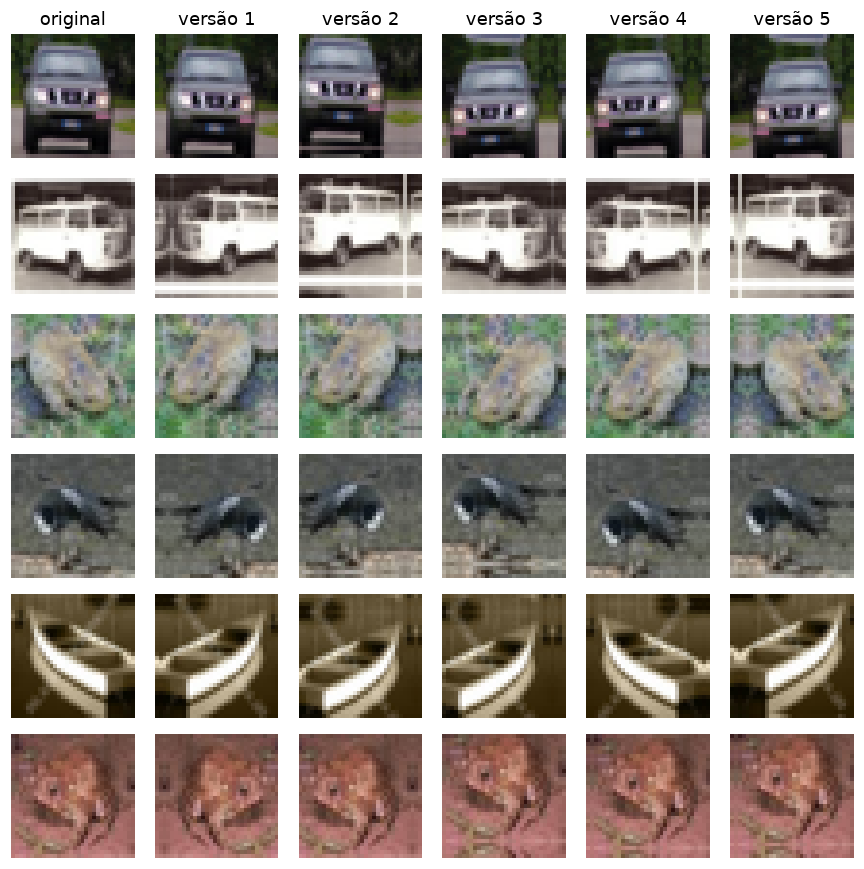

In [26]:
fixar_semente()
exemplos = X_treino[:6]
versoes = [exemplos] + [aumentar_dados(exemplos) for _ in range(5)]

fig, eixos = plt.subplots(6, 6, figsize=(8, 8))
for linha in range(6):
    for coluna in range(6):
        eixos[linha, coluna].imshow(para_exibir(versoes[coluna][linha], media, desvio))
        eixos[linha, coluna].axis("off")
eixos[0, 0].set_title("original")
for coluna in range(1, 6):
    eixos[0, coluna].set_title(f"versão {coluna}")
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "3_augmentation.png", bbox_inches="tight")
plt.show()

Cada versão é a mesma imagem deslocada alguns pixels e, às vezes, espelhada. O objeto continua o mesmo, mas os pixels mudam de lugar. Isso ensina a CNN que a posição exata do objeto não importa.

---
# Item a: MLP

## Arquitetura

In [27]:
fixar_semente()
mlp = MLP().to(device)
print(mlp)
print("Total de pesos treináveis:", sum(p.numel() for p in mlp.parameters()))

MLP(
  (rede): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=1024, bias=True)
    (2): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=1024, out_features=512, bias=True)
    (6): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU()
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=512, out_features=256, bias=True)
    (10): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU()
    (12): Dropout(p=0.3, inplace=False)
    (13): Linear(in_features=256, out_features=10, bias=True)
  )
)
Total de pesos treináveis: 3809034


A MLP tem:
- entrada: a imagem achatada em 3072 números;
- três camadas escondidas com 1024, 512 e 256 neurônios, cada uma com BatchNorm, ReLU e dropout de 30%;
- saída com 10 neurônios, um por classe.

São cerca de 3,8 milhões de pesos. Quase todos estão na primeira camada (3072 x 1024 = 3,1 milhões), porque cada pixel de cada cor se liga a todos os neurônios.

## Treinando
Otimizador AdamW com taxa de aprendizado 0,001 e weight decay 0,0001, lotes de 128 imagens, até 60 épocas. O treino para se a acurácia da validação ficar 8 épocas sem melhorar.

In [28]:
fixar_semente()
historico_mlp = treinar(mlp, dados, epocas=60, lr=1e-3, weight_decay=1e-4, paciencia=8, nome="MLP")

MLP:   0%|                                                                          | 0/60 [00:00<?, ?época/s]

MLP:   2%|       | 1/60 [00:02<02:34,  2.62s/época, acc_treino=0.384, acc_val=0.459, erro_val=1.517, melhor=1]

MLP:   3%|▏      | 2/60 [00:04<02:15,  2.34s/época, acc_treino=0.461, acc_val=0.492, erro_val=1.413, melhor=2]

MLP:   5%|▎      | 3/60 [00:07<02:12,  2.32s/época, acc_treino=0.494, acc_val=0.498, erro_val=1.377, melhor=3]

MLP:   7%|▍      | 4/60 [00:09<02:09,  2.32s/época, acc_treino=0.515, acc_val=0.524, erro_val=1.320, melhor=4]

MLP:   8%|▌      | 5/60 [00:11<02:05,  2.29s/época, acc_treino=0.534, acc_val=0.531, erro_val=1.304, melhor=5]

... (21 outputs left out)

MLP:  45%|██▎  | 27/60 [01:02<01:15,  2.30s/época, acc_treino=0.760, acc_val=0.584, erro_val=1.343, melhor=21]

MLP:  47%|██▎  | 28/60 [01:04<01:12,  2.28s/época, acc_treino=0.767, acc_val=0.584, erro_val=1.333, melhor=21]

MLP:  47%|██▎  | 28/60 [01:07<01:16,  2.40s/época, acc_treino=0.776, acc_val=0.584, erro_val=1.368, melhor=21]

Parou na época 29: a acurácia da validação ficou 8 épocas sem melhorar.
Melhor época: 21 (acurácia na validação = 0.5842). Tempo: 1.1 min


## Curvas de erro de treino e de validação

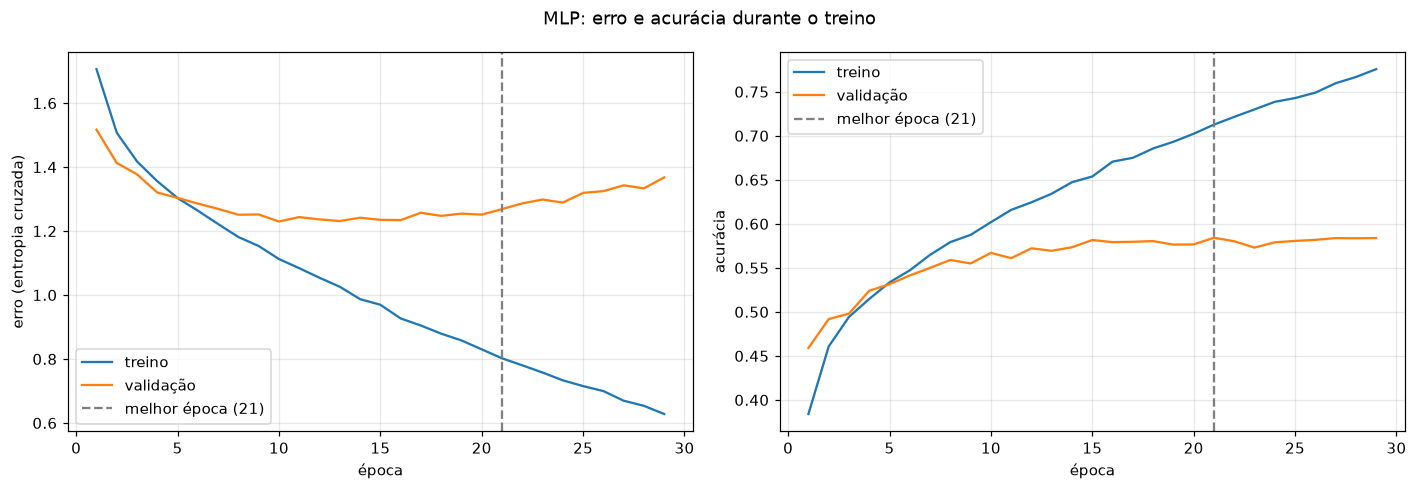

In [29]:
grafico_curvas(historico_mlp, "MLP: erro e acurácia durante o treino", arquivo="3a_curvas_mlp.png")

O que observar:
- O erro de treino cai o tempo todo, mas o erro de validação para de cair por volta da época 10 e começa a subir perto da época 20. É um sinal claro de overfitting: a rede passa a decorar as imagens de treino.
- Na acurácia, o treino passa de 75% e continua subindo, enquanto a validação fica parada perto de 58%.
- O early stopping parou o treino na época 29, porque a validação ficou 8 épocas sem melhorar. Voltamos para os pesos da melhor época, a 21 (58,4% na validação).
- Mesmo com dropout e BatchNorm, a MLP não passa de cerca de 58%. A CNN do item b usa data augmentation e OneCycle, e esta MLP não. No final do notebook treinamos a MLP com a mesma receita da CNN para ver se o limite vem da arquitetura ou do treino.

## Matriz de confusão no teste

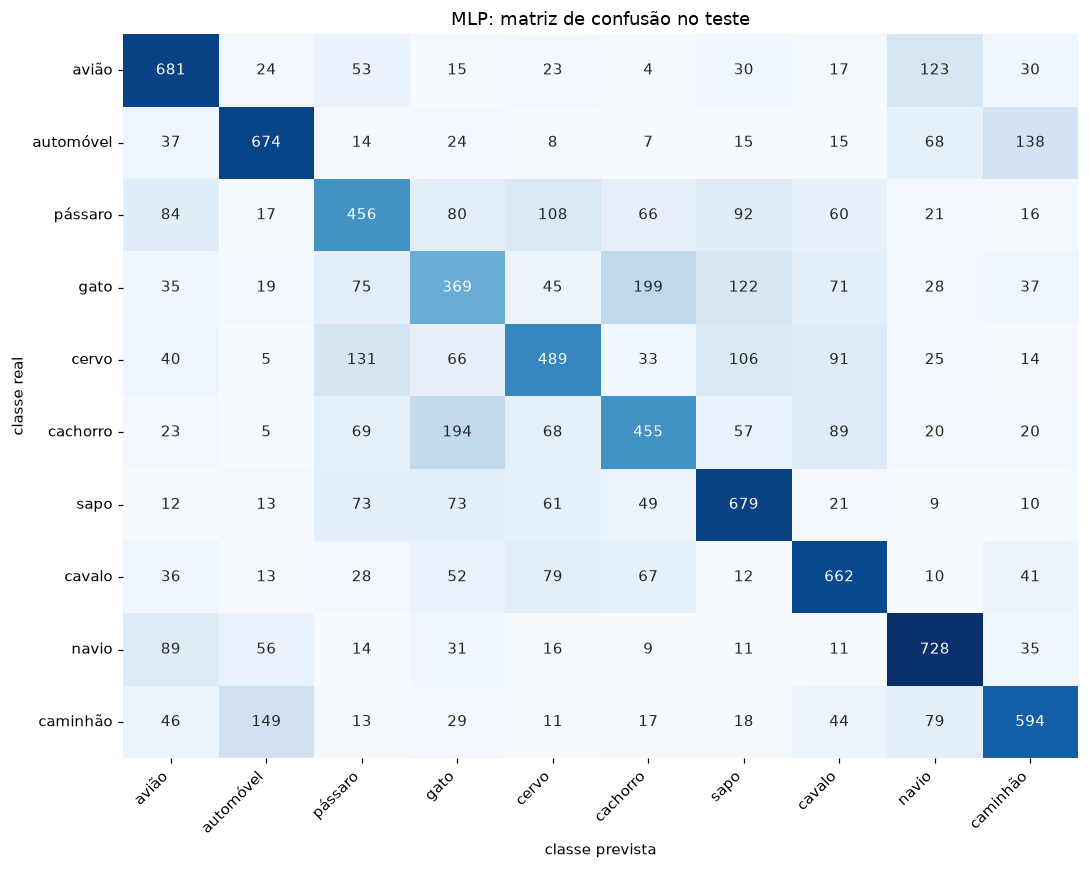

In [30]:
previstos_mlp, probabilidades_mlp = prever(mlp, X_teste)
matriz_mlp = grafico_matriz_confusao(classes_teste, previstos_mlp, "MLP: matriz de confusão no teste", arquivo="3a_matriz_mlp.png")

O que observar:
- A acurácia da MLP no teste foi 57,9%. Acerta bem mais que um chute (10%), mas erra muito.
- A maior confusão é entre gato e cachorro: 199 gatos foram classificados como cachorro e 194 cachorros como gato.
- Automóvel e caminhão também se confundem bastante (149 caminhões viraram automóvel e 138 automóveis viraram caminhão), e avião é confundido com navio (123), provavelmente por causa do fundo azul.
- Os animais (pássaro, gato, cervo, cachorro) são as classes mais difíceis. Os erros se espalham por várias colunas, o que mostra que a MLP não está entendendo bem a forma do animal.

## Acurácia no teste

In [31]:
acuracia_mlp = (previstos_mlp == classes_teste).mean()
print(f"Acurácia da MLP no teste: {acuracia_mlp:.2%}")

Acurácia da MLP no teste: 57.87%


In [32]:
maiores_confusoes(matriz_mlp)

,classe real,prevista como,imagens
0,gato,cachorro,199
1,cachorro,gato,194
2,caminhão,automóvel,149
3,automóvel,caminhão,138
4,cervo,pássaro,131


---
# Item b: CNN

## Arquitetura

In [33]:
fixar_semente()
cnn = CNN().to(device)
print(cnn)
print("Total de pesos treináveis:", sum(p.numel() for p in cnn.parameters()))

CNN(
  (bloco1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0.1, inplace=False)
  )
  (bloco2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dro

A CNN tem:
- bloco 1: duas convoluções com 64 filtros de 3 x 3, BatchNorm e ReLU, MaxPool (32 x 32 vira 16 x 16) e dropout de 10%;
- bloco 2: duas convoluções com 128 filtros, MaxPool (16 x 16 vira 8 x 8) e dropout de 20%;
- bloco 3: duas convoluções com 256 filtros, MaxPool (8 x 8 vira 4 x 4) e dropout de 30%;
- global average pooling: a média de cada um dos 256 mapas;
- camada linear de 256 para 10 classes.

A CNN tem cerca de 1,15 milhão de pesos, menos de um terço da MLP. Isso acontece porque cada filtro de 3 x 3 é usado em todas as posições da imagem: a rede reaproveita os mesmos pesos, em vez de ter um peso para cada pixel.

## Treinando
- Otimizador AdamW com weight decay 0,0005 e agendador OneCycle, com taxa de aprendizado máxima de 0,003.
- 40 épocas com lotes de 128 imagens e data augmentation.
- Guardamos em arquivo os pesos antes do treino (época 0, ainda com os valores sorteados), os das épocas 1, 5 e 40, e também os pesos da melhor época (`cnn_final.pt`). A Questão 4 usa os das épocas 0, 1 e 5 e o `cnn_final.pt`, para comparar o que a rede tinha antes de aprender com o começo, o meio e o fim do treino.

Aqui não usamos early stopping: com o OneCycle a taxa de aprendizado só fica bem pequena nas últimas épocas, e é nelas que a rede costuma dar o último salto de acurácia. Mesmo assim, guardamos os pesos da melhor época na validação.

In [34]:
fixar_semente()
extras = {"media": media.cpu(), "desvio": desvio.cpu()}
salvar_modelo(cnn, PASTA_MODELOS / "cnn_epoca_00.pt", 0, extras)  # pesos sorteados, antes de qualquer treino
historico_cnn = treinar(cnn, dados, epocas=40, lr=3e-3, weight_decay=5e-4, one_cycle=True, aumentar=True,
                        salvar_epocas=(1, 5, 40), nome_arquivo="cnn", extras=extras, nome="CNN")
salvar_modelo(cnn, PASTA_MODELOS / "cnn_final.pt", historico_cnn["melhor_epoca"], extras)

CNN:   0%|                                                                          | 0/40 [00:00<?, ?época/s]

CNN:   2%|▏      | 1/40 [00:07<04:46,  7.34s/época, acc_treino=0.469, acc_val=0.555, erro_val=1.246, melhor=1]

CNN:   5%|▎      | 2/40 [00:14<04:25,  6.99s/época, acc_treino=0.607, acc_val=0.622, erro_val=1.060, melhor=2]

CNN:   8%|▌      | 3/40 [00:20<04:12,  6.82s/época, acc_treino=0.664, acc_val=0.675, erro_val=0.928, melhor=3]

CNN:  10%|▋      | 4/40 [00:27<04:02,  6.73s/época, acc_treino=0.708, acc_val=0.739, erro_val=0.782, melhor=4]

CNN:  12%|▉      | 5/40 [00:33<03:54,  6.70s/época, acc_treino=0.738, acc_val=0.704, erro_val=0.903, melhor=4]

... (33 outputs left out)

CNN:  98%|████▉| 39/40 [04:07<00:06,  6.21s/época, acc_treino=0.975, acc_val=0.923, erro_val=0.260, melhor=38]

CNN: 100%|█████| 40/40 [04:13<00:00,  6.18s/época, acc_treino=0.974, acc_val=0.922, erro_val=0.262, melhor=38]

CNN: 100%|█████| 40/40 [04:13<00:00,  6.34s/época, acc_treino=0.974, acc_val=0.922, erro_val=0.262, melhor=38]

Melhor época: 38 (acurácia na validação = 0.9240). Tempo: 4.2 min


## Curvas de erro de treino e de validação

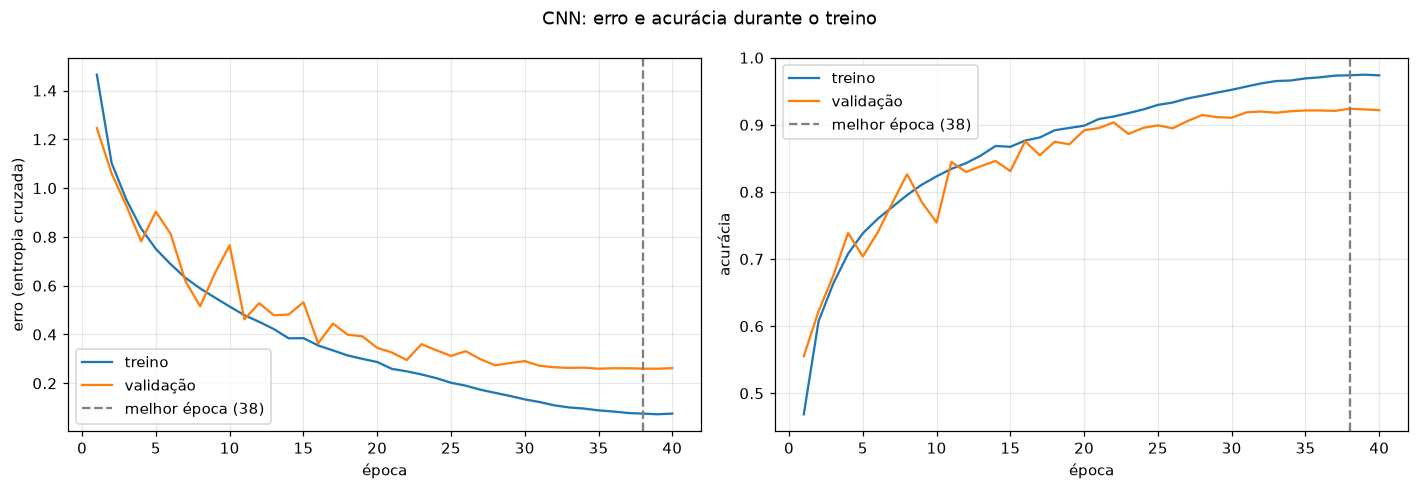

In [35]:
grafico_curvas(historico_cnn, "CNN: erro e acurácia durante o treino", arquivo="3b_curvas_cnn.png")

O que observar:
- Treino e validação caem juntos durante quase todo o treino. A curva de validação oscila bastante nas primeiras 15 épocas, por causa da taxa de aprendizado alta no início do OneCycle, e depois fica estável.
- No final a taxa de aprendizado fica bem pequena, e as duas curvas se estabilizam. A melhor época foi a 38, com 92,4% de acurácia na validação.
- Existe uma diferença entre treino (cerca de 97%) e validação (cerca de 92%), mas o erro de validação não tem tendência de subir no final: depois das oscilações do começo, ele só cai ou fica estável. Então a rede está generalizando, e não só decorando.
- O treino é feito com data augmentation (imagens espelhadas e deslocadas), então a curva de treino é calculada em imagens "mais difíceis" que as de validação.

## Matriz de confusão no teste

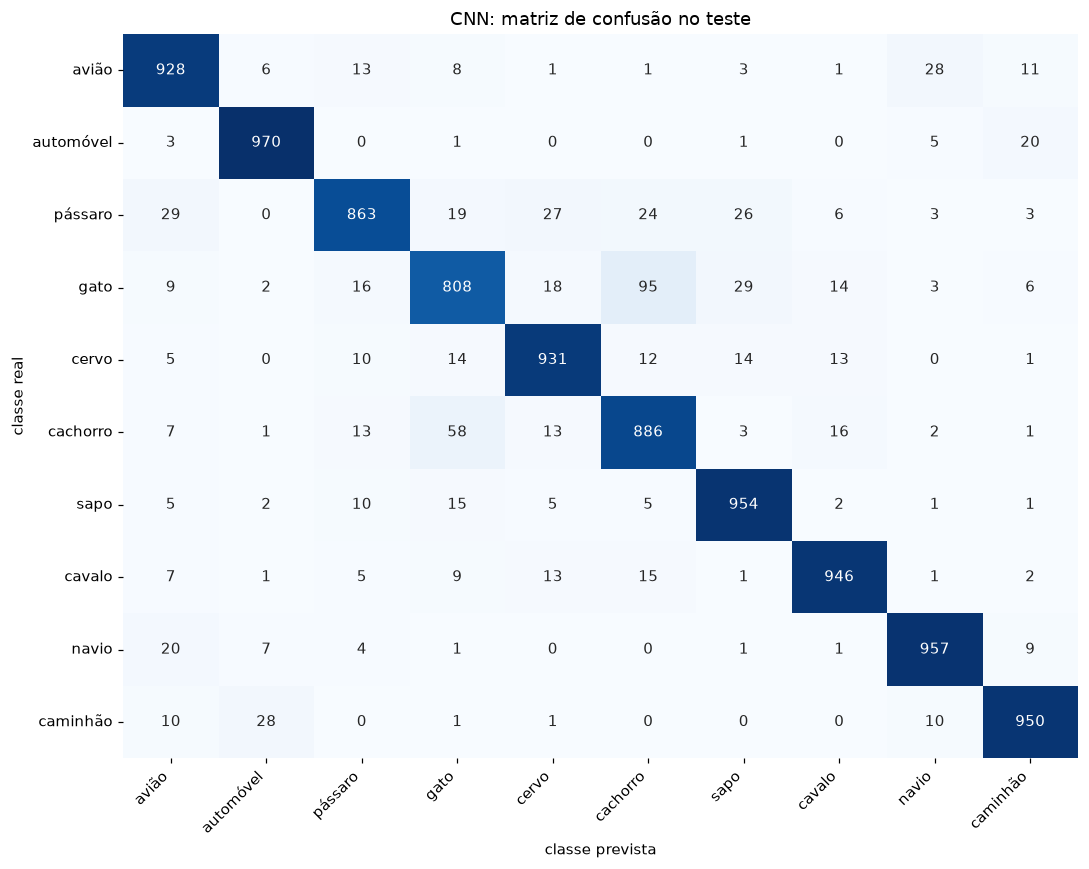

In [36]:
previstos_cnn, probabilidades_cnn = prever(cnn, X_teste)
matriz_cnn = grafico_matriz_confusao(classes_teste, previstos_cnn, "CNN: matriz de confusão no teste", arquivo="3b_matriz_cnn.png")

O que observar:
- A acurácia da CNN no teste foi 91,9%. A diagonal ficou bem mais escura que a da MLP.
- O par mais confundido continua sendo gato e cachorro (95 gatos viraram cachorro e 58 cachorros viraram gato), mas são menos da metade dos erros da MLP nesse par.
- Os outros erros aparecem entre classes realmente parecidas ou com fundos parecidos: caminhão e automóvel (28 e 20), avião e navio (28 e 20), pássaro e avião (29) e gato e sapo (29).
- Quase não há confusão entre veículos e animais. A CNN aprendeu a separar bem os dois grandes grupos.

## Acurácia no teste

In [37]:
acuracia_cnn = (previstos_cnn == classes_teste).mean()
print(f"Acurácia da CNN no teste: {acuracia_cnn:.2%}")

Acurácia da CNN no teste: 91.93%


In [38]:
maiores_confusoes(matriz_cnn)

,classe real,prevista como,imagens
0,gato,cachorro,95
1,cachorro,gato,58
2,pássaro,avião,29
3,gato,sapo,29
4,caminhão,automóvel,28


---
# Verificando overfitting
Para o treino medimos a acurácia nas imagens originais, sem data augmentation.

In [39]:
pd.concat({
    "MLP": tabela_overfitting(mlp, conjuntos),
    "CNN": tabela_overfitting(cnn, conjuntos),
}, axis=1).round(4)

,MLP,CNN
,acurácia,acurácia
treino,0.8274,0.9932
validação,0.5844,0.9240
teste,0.5787,0.9193


Na tabela, a acurácia no treino é medida sem dropout e sem data augmentation, por isso é maior que a da curva.

- MLP: 82,7% no treino, mas só 58,4% na validação e 57,9% no teste. São cerca de 25 pontos de diferença. A MLP tem overfitting forte: decora as imagens de treino e não generaliza. O early stopping e o dropout limitam o estrago, mas não resolvem.
- CNN: 99,3% no treino, 92,4% na validação e 91,9% no teste. A diferença é de cerca de 7 pontos, bem menor. Existe um pouco de overfitting, mas a rede generaliza bem.
- Nos dois casos, validação e teste ficam muito próximos. Isso mostra que escolher o modelo pela validação foi uma boa estimativa do resultado em imagens novas.

---
# Comparando a MLP e a CNN

## Acurácia por classe

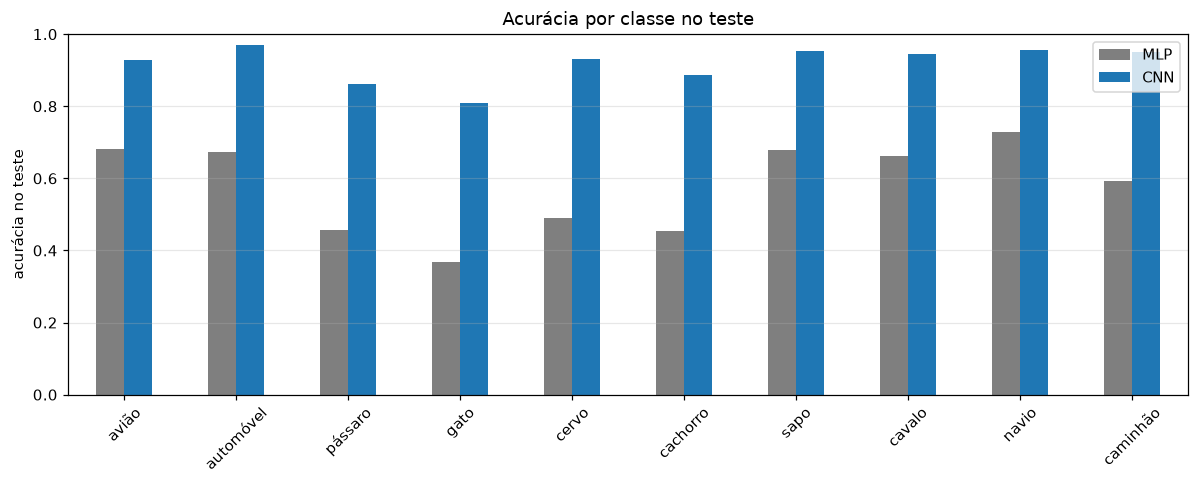

In [40]:
por_classe = pd.DataFrame({
    "MLP": acuracia_por_classe(classes_teste, previstos_mlp),
    "CNN": acuracia_por_classe(classes_teste, previstos_cnn),
})

por_classe.plot.bar(figsize=(11, 4.5), rot=45, color=["tab:gray", "tab:blue"])
plt.ylabel("acurácia no teste")
plt.ylim(0, 1)
plt.title("Acurácia por classe no teste")
plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "3_comparacao_classes.png", bbox_inches="tight")
plt.show()

O que observar:
- A CNN ganha da MLP em todas as 10 classes.
- As classes mais difíceis são as mesmas nos dois modelos: gato (36,9% na MLP e 80,8% na CNN), pássaro (45,6% e 86,3%) e cachorro (45,5% e 88,6%).
- A maior melhora aparece justamente nos animais: cervo sobe 44 pontos, gato 44, cachorro 43 e pássaro 41. Para reconhecer um animal é preciso entender formas como orelhas, patas e focinho, e é isso que as convoluções fazem bem.
- Os veículos já eram as classes mais fáceis para a MLP, por causa da cor e do fundo. Mesmo assim a CNN sobe todos para mais de 92%.

## MLP com a mesma receita de treino da CNN
A comparação acima não é totalmente justa: a CNN foi treinada com data augmentation e OneCycle, e a MLP do item a não. Para separar as duas coisas, treinamos uma segunda MLP, igual à do item a, com exatamente a mesma receita da CNN (40 épocas, data augmentation, OneCycle com taxa máxima de 0,003 e weight decay de 0,0005). Assim a única diferença que sobra entre ela e a CNN é a arquitetura.

In [41]:
fixar_semente()
mlp_receita = MLP().to(device)
historico_mlp_receita = treinar(mlp_receita, dados, epocas=40, lr=3e-3, weight_decay=5e-4, one_cycle=True,
                                aumentar=True, nome="MLP (receita da CNN)")

MLP (receita da CNN):   0%|                                                         | 0/40 [00:00<?, ?época/s]

MLP (receita da CNN):   2%| | 1/40 [00:02<01:18,  2.01s/época, acc_treino=0.322, acc_val=0.419, erro_val=1.611

MLP (receita da CNN):   8%| | 3/40 [00:05<01:13,  2.00s/época, acc_treino=0.400, acc_val=0.466, erro_val=1.473

MLP (receita da CNN):  10%| | 4/40 [00:07<01:11,  2.00s/época, acc_treino=0.410, acc_val=0.475, erro_val=1.451

MLP (receita da CNN):  15%|▏| 6/40 [00:11<01:07,  1.98s/época, acc_treino=0.430, acc_val=0.483, erro_val=1.436

MLP (receita da CNN):  20%|▏| 8/40 [00:15<01:03,  1.97s/época, acc_treino=0.441, acc_val=0.497, erro_val=1.384

... (18 outputs left out)

MLP (receita da CNN):  92%|▉| 37/40 [01:14<00:06,  2.08s/época, acc_treino=0.561, acc_val=0.603, erro_val=1.10

MLP (receita da CNN):  98%|▉| 39/40 [01:18<00:02,  2.02s/época, acc_treino=0.566, acc_val=0.603, erro_val=1.09

MLP (receita da CNN): 100%|█| 40/40 [01:20<00:00,  2.01s/época, acc_treino=0.564, acc_val=0.602, erro_val=1.10

Melhor época: 38 (acurácia na validação = 0.6044). Tempo: 1.3 min


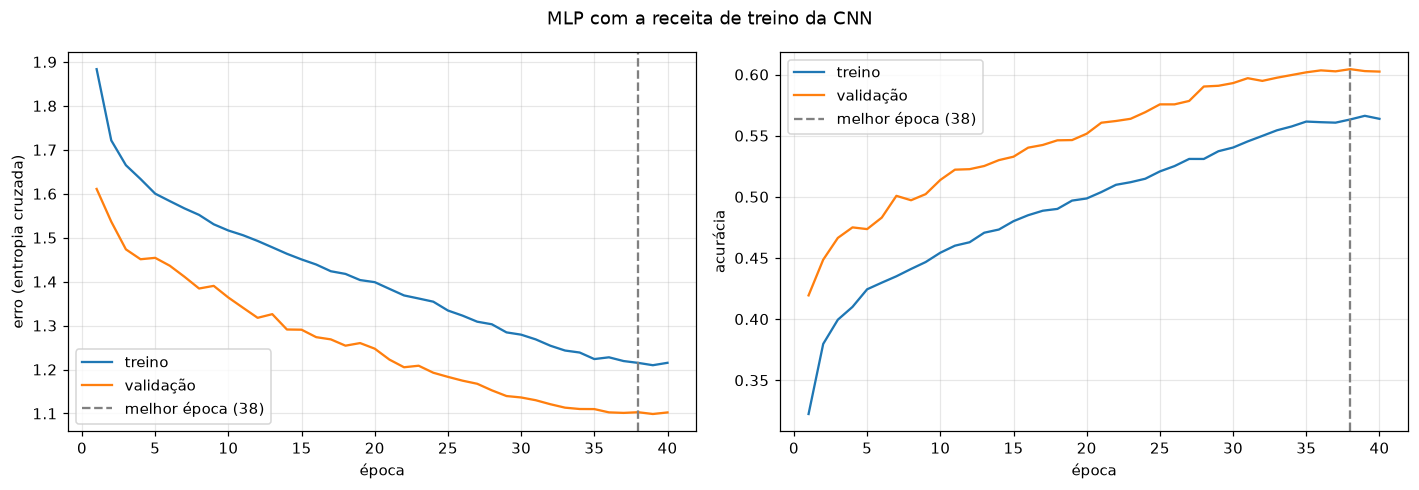

In [42]:
grafico_curvas(historico_mlp_receita, "MLP com a receita de treino da CNN", arquivo="3_curvas_mlp_receita.png")

In [43]:
previstos_mlp_receita, _ = prever(mlp_receita, X_teste)
acuracia_mlp_receita = (previstos_mlp_receita == classes_teste).mean()

pd.concat({
    "MLP (item a)": tabela_overfitting(mlp, conjuntos),
    "MLP (receita da CNN)": tabela_overfitting(mlp_receita, conjuntos),
    "CNN": tabela_overfitting(cnn, conjuntos),
}, axis=1).round(4)

,MLP (item a),MLP (receita da CNN),CNN
,acurácia,acurácia,acurácia
treino,0.8274,0.6483,0.9932
validação,0.5844,0.6044,0.9240
teste,0.5787,0.6096,0.9193


O que observar:
- Com a receita da CNN, a MLP sobe de 57,9% para 61,0% no teste. A data augmentation e o OneCycle ajudam, mas só cerca de 3 pontos.
- O overfitting da MLP desaparece: a acurácia no treino cai de 82,7% para 64,8%, bem perto da validação (60,4%) e do teste (61,0%). Nas curvas, a validação fica até acima do treino, porque o treino é medido em imagens deslocadas e espelhadas e com dropout ligado.
- Antes a MLP decorava o treino. Agora ela não decora, mas também não consegue aprender bem o próprio treino (65%). O que falta é um jeito de aproveitar a estrutura da imagem, e isso depende da arquitetura.
- A CNN, com a mesma receita e menos de um terço dos pesos, chega a 91,9%. Dos 34 pontos de diferença entre a MLP do item a e a CNN, cerca de 3 vêm do jeito de treinar e cerca de 31 vêm da arquitetura.
- Obs.: a taxa de aprendizado e o weight decay desta receita foram escolhidos para a CNN, não para a MLP. Uma busca feita só para a MLP poderia render mais alguns pontos, mas não os 31 que faltam.

## Resumo

In [44]:
pd.DataFrame({
    "pesos treináveis": [sum(p.numel() for p in m.parameters()) for m in (mlp, mlp_receita, cnn)],
    "épocas treinadas": [len(h["erro_treino"]) for h in (historico_mlp, historico_mlp_receita, historico_cnn)],
    "acurácia no teste": [acuracia_mlp, acuracia_mlp_receita, acuracia_cnn],
}, index=["MLP (item a)", "MLP (receita da CNN)", "CNN"])

,pesos treináveis,épocas treinadas,acurácia no teste
MLP (item a),3809034,29,0.5787
MLP (receita da CNN),3809034,40,0.6096
CNN,1149770,40,0.9193


# Conclusão

- A MLP chegou a 57,9% de acurácia no teste e a CNN chegou a 91,9%, mesmo tendo cerca de 3 vezes menos pesos (1,1 milhão contra 3,8 milhões).
- A MLP recebe a imagem "achatada" em uma lista de 3072 números. Ela perde a noção de quais pixels são vizinhos e precisa aprender cada padrão separadamente para cada posição da imagem. Por isso decora o treino (83%) e generaliza mal.
- A CNN olha pequenos pedaços da imagem e usa o mesmo filtro em todas as posições. Assim ela reconhece uma borda, uma textura ou uma orelha em qualquer lugar da foto. Juntando isso com BatchNorm, dropout e data augmentation, o overfitting ficou pequeno (99% no treino e 92% no teste).
- A diferença vem quase toda da arquitetura. Treinando a MLP com a mesma receita da CNN (data augmentation e OneCycle), ela sobe só para 61,0%: para de decorar o treino, mas continua 31 pontos abaixo da CNN.
- Nos dois modelos o erro mais comum é gato com cachorro, que também é difícil para pessoas em imagens de 32x32 pixels.
- Para a Q4 salvamos os pesos da CNN antes do treino (época 0), nas épocas 1, 5 e 40 e os da melhor época (a 38), para ver o que a rede aprendeu ao longo do treino.
- Cada modelo foi treinado uma única vez, com uma semente. Outra semente (ou outra placa de vídeo) muda os números em alguns décimos de ponto, então diferenças desse tamanho não devem ser interpretadas.